This script was intially created on the Calling the GEM Database for QC  [Scott's Copy].ipynb notebook, then split and brought over here for standalone use

In [1]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# define path
goget_folder = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)'
iterations_alt = goget_folder + '/GOGET Iterations/Alternative Formats of GOGET/'
GOGET_data = iterations_alt + '/all-fields-2026-01-26T230912.csv'
GOGET_official_data = iterations_alt + 'goget-field-export-2026-manual-keep-for-summary.xlsx - Field-level main data.csv'
brief_fold = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/Reports/Q1 2026 GOGET briefing'
data_viz_fold = brief_fold + '/Data Viz/Data'
qc_dump_folder = goget_folder + '/QC/QC Output Dump/'


In [3]:
# import pandas
import pandas as pd

In [4]:
# attempt to recreate using David's data download
# bring in official export
official_export = pd.read_csv(GOGET_official_data)

# apply filter logic:
# Define common filters for 'field' and 'conventional' production, excluding certain name prefixes
condition_main_filters = \
    (official_export['Production Type'] == 'conventional')

# Define prefixes to filter out (e.g., 'FGP', 'Phase', 'Shale')
prefixes_to_filter = ['FGP', 'Phase','Shale','Redevelopment','Mad Dog Southwest','redevelopment','phase']
condition_no_prefixes = ~official_export['Unit Name'].str.contains('|'.join(prefixes_to_filter), na=False)

# Combine all conditions: (Main filters AND No prefixes) OR (Asset (Federal offshore, United States))
final_filter = (condition_main_filters & condition_no_prefixes)

official_export_filter = official_export[final_filter]


# Calculate the discovery to start year for each unit. If both values are not blank Start Year - Discovery Year
official_export_filter['Discovery to Start Year'] = official_export_filter['Production start year'] - official_export_filter['Discovery year']

# Drop NaN values from 'Discovery to Start Year'
official_export_filter = official_export_filter.dropna(subset=['Discovery to Start Year'])

# add in missing 2025 data, for some reason this is excluded from the table of the export
# unit_id: 100001081837, 	Discovery Year: 1970	Start Year: 2025	Discovery to Start Year: 55
# new_entries = [
#     {
#         'unit_id': 100001081837, # Quiluma
#         'Discovery year': 1970,
#         'Fuel type': 'gas',
#         'Production start year': 2025,
#         'Discovery to Start Year': 55
#     },
#     #     {
#     #     'unit_id': 100000310995, # Assa North-Ohaji South
#     #     'Discovery year': 1992,
#     #     'Production start year': 2025,
#     #     'Discovery to Start Year': 33
#     # },
# {
#         'unit_id': 100001081838, # Maboqueiro
#         'Discovery year': 1995,
#         'Fuel type': 'gas',
#         'Production start year': 2025,
#         'Discovery to Start Year': 30
#     },
# ]

# official_export_filter = pd.concat([
#     official_export_filter,
#     pd.DataFrame(new_entries)
# ], ignore_index=True)


# --- Step 4: Calculate the annual average discovery_start_years by start year ---
official_export_filter_avg = official_export_filter.groupby('Production start year')['Discovery to Start Year'].mean().reset_index()
official_export_filter_median = official_export_filter.groupby('Production start year')['Discovery to Start Year'].median().reset_index()

# --- Step 5: Define Eras ---
# five year intervals
# eras = {
#     '1900-1954': (1900, 1954),
#     '1955-1994': (1955, 1994),
#     '1995-1999': (1995, 1999),
#     '2000-2009': (2000, 2004),
#     '2005-2014': (2005, 2014),
#     '2015-2020': (2015, 2020),
#     '2021-2024': (2021, 2024),
#     '2025': (2025, 2025)
# }
# # ten year intervals
eras = {
    '1900-1959': (1900, 1950),
    '1960-1980': (1960, 1980),
    '1981-1999': (1981, 1999),
    '2000-2009': (2000, 2009),
    '2010-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# # even buckets
# eras = {
#     '1900-1985': (1900, 1985),
#     '1956-2000': (1986, 2000),
#     '2001-2015': (2001, 2015),
#     '2016-2024': (2016, 2024),
#     '2025': (2025, 2025)
# }


# --- Step 6: Group by Era ---
# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years_avg
official_export_filter_avg['Era'] = official_export_filter_avg['Production start year'].apply(get_era)
official_export_filter_median['Era'] = official_export_filter_median['Production start year'].apply(get_era)

# Group by 'Era' and calculate the mean of 'Discovery to Start Year'
official_export_filter_by_era = official_export_filter_avg.groupby('Era')['Discovery to Start Year'].mean().reset_index()
official_export_filter_by_era_median = official_export_filter_median.groupby('Era')['Discovery to Start Year'].median().reset_index()

# --- Step 7: Display Results ---
display(official_export_filter_by_era)
display(official_export_filter_by_era_median)

/tmp/ipykernel_10594/3750509651.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  official_export_filter['Discovery to Start Year'] = official_export_filter['Production start year'] - official_export_filter['Discovery year']


,Era,Discovery to Start Year
0,1900-1959,4.513889
1,1960-1980,4.883318
2,1981-1999,10.045919
3,2000-2009,13.162439
4,2010-2020,15.690124
5,2021-2024,14.976110
6,2025,15.125000
7,Other,6.972980


,Era,Discovery to Start Year
0,1900-1959,3.75
1,1960-1980,3.50
2,1981-1999,8.00
3,2000-2009,9.75
4,2010-2020,10.00
5,2021-2024,9.50
6,2025,8.50
7,Other,2.00


In [5]:
# count fields per each era
official_export_filter_for_count = official_export_filter.copy()

official_export_filter_for_count['Era'] = official_export_filter_for_count['Production start year'].apply(get_era)
official_export_filter_for_count_grouped = official_export_filter_for_count.groupby('Era').size().reset_index(name='Count')

In [6]:
official_export_filter_for_count_grouped

,Era,Count
0,1900-1959,22
1,1960-1980,235
2,1981-1999,478
3,2000-2009,367
4,2010-2020,415
5,2021-2024,145
6,2025,24
7,Other,44


In [7]:
# examine 2015-2020
range_to_check = '2010-2020'
official_export_filter_avg[official_export_filter_avg['Era'] == range_to_check]

,Production start year,Discovery to Start Year,Era
71,2010.0,13.190476,2010-2020
72,2011.0,15.222222,2010-2020
73,2012.0,14.000000,2010-2020
74,2013.0,13.219512,2010-2020
75,2014.0,18.204545,2010-2020
76,2015.0,12.755556,2010-2020
77,2016.0,17.826923,2010-2020
78,2017.0,14.869565,2010-2020
79,2018.0,18.000000,2010-2020
80,2019.0,19.769231,2010-2020


In [8]:
# examine outlier years
year = 2019

official_export_filter[official_export_filter['Production start year'] == year].sort_values(by='Discovery to Start Year', ascending=False)


,Project ID,Unit Name,Unit name local script,Fuel type,Country,Subnational unit,Production Type,Status,Status detail,Status year,...,Wiki URL (field),Name Other,Latitude,Longitude,Location accuracy,Onshore/Offshore,Field outline (WKT),Basin,Block(s),Discovery to Start Year
6900,L100000311242,Ubima Oil and Gas Field (Nigeria),NaN,oil and gas,Nigeria,NaN,conventional,operating,NaN,2019.0,...,https://www.gem.wiki/Ubima_Oil_and_Gas_Field_(...,NaN,NaN,NaN,NaN,onshore,NaN,NaN,OML 17; PML 7,56.0
2098,L100000312035,E6 Oil and Gas Field (Malaysia),NaN,oil and gas,Malaysia,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/E6_Oil_and_Gas_Field_(Mal...,NaN,4.282712,112.384853,exact,offshore,"POLYGON ((112.395622022 4.33822959700006,112.4...",NaN,SK308,49.0
7610,L100000318977,Zapadno-Tarkosalinskoye (Gazprom Neft) Oil and...,"Западно-Таркосалинское (Газпром нефть, нефтяны...",oil and gas,Russia,Yamalo-Nenets Autonomous Okrug,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Zapadno-Tarkosalinskoye_(...,West Tarkosalinskoye,64.192700,75.669600,approximate,onshore,NaN,NaN,Zapadno-Tarkosalinsky,47.0
3588,L100000312144,Khokhryakovskoye Oil Field (Khanty-Mansi Auton...,Хохряковское,oil,Russia,Khanty-Mansi Autonomous Okrug,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Khokhryakovskoye_Oil_Fiel...,NaN,61.530000,79.390000,approximate,onshore,NaN,NaN,NaN,47.0
3847,L100000302100,Lancaster Oil and Gas Field (United Kingdom),NaN,oil and gas,United Kingdom,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Lancaster_Oil_and_Gas_Fie...,NaN,60.189400,-3.841000,exact,offshore,NaN,NaN,NaN,45.0
4333,L100000302127,Mariner Oil and Gas Field (United Kingdom),NaN,oil and gas,United Kingdom,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Mariner_Oil_and_Gas_Field...,NaN,59.589100,1.075100,exact,offshore,NaN,NaN,9/11,37.0
6989,L100000304554,Utgard Oil and Gas Field (Norway),NaN,oil and gas,Norway,NaN,conventional,operating,NaN,2025.0,...,https://www.gem.wiki/Utgard_Oil_and_Gas_Field_...,NaN,58.370500,1.554600,exact,offshore,"POLYGON ((1.54077835130402 58.343747354087725,...",NaN,NaN,37.0
1539,L100000312042,Chayandinskoye (Gazprom) Oil and Gas Asset (Re...,Чаяндинское (Газпром),oil and gas,Russia,Republic of Sakha,conventional,operating,NaN,2023.0,...,https://www.gem.wiki/Chayandinskoye_(Gazprom)_...,NaN,60.249000,112.282000,exact,onshore,NaN,Lena-Tunguska,Chayandinsky,36.0
6990,L100000302236,Utgard Oil and Gas Field (United Kingdom),NaN,oil and gas,United Kingdom,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Utgard_Oil_and_Gas_Field_...,NaN,58.359000,1.526200,exact,offshore,NaN,NaN,NaN,36.0
1538,L100000319006,Chayandinskoye (Gazprom Neft) Oil and Gas Asse...,"Чаяндинское (Газпром нефть, нефтяные залежи)",oil and gas,Russia,Republic of Sakha,conventional,operating,NaN,2023.0,...,https://www.gem.wiki/Chayandinskoye_(Gazprom_N...,NaN,60.249000,112.282000,exact,onshore,NaN,Lena-Tunguska,Chayandinsky,36.0


In [10]:
# examine outlier years
country = "Bangladesh"

official_export_filter[official_export_filter['Production start year'] == year].sort_values(by='Discovery to Start Year', ascending=False)

,Project ID,Unit Name,Unit name local script,Fuel type,Country,Subnational unit,Production Type,Status,Status detail,Status year,...,Wiki URL (field),Name Other,Latitude,Longitude,Location accuracy,Onshore/Offshore,Field outline (WKT),Basin,Block(s),Discovery to Start Year
6900,L100000311242,Ubima Oil and Gas Field (Nigeria),NaN,oil and gas,Nigeria,NaN,conventional,operating,NaN,2019.0,...,https://www.gem.wiki/Ubima_Oil_and_Gas_Field_(...,NaN,NaN,NaN,NaN,onshore,NaN,NaN,OML 17; PML 7,56.0
2098,L100000312035,E6 Oil and Gas Field (Malaysia),NaN,oil and gas,Malaysia,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/E6_Oil_and_Gas_Field_(Mal...,NaN,4.282712,112.384853,exact,offshore,"POLYGON ((112.395622022 4.33822959700006,112.4...",NaN,SK308,49.0
7610,L100000318977,Zapadno-Tarkosalinskoye (Gazprom Neft) Oil and...,"Западно-Таркосалинское (Газпром нефть, нефтяны...",oil and gas,Russia,Yamalo-Nenets Autonomous Okrug,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Zapadno-Tarkosalinskoye_(...,West Tarkosalinskoye,64.192700,75.669600,approximate,onshore,NaN,NaN,Zapadno-Tarkosalinsky,47.0
3588,L100000312144,Khokhryakovskoye Oil Field (Khanty-Mansi Auton...,Хохряковское,oil,Russia,Khanty-Mansi Autonomous Okrug,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Khokhryakovskoye_Oil_Fiel...,NaN,61.530000,79.390000,approximate,onshore,NaN,NaN,NaN,47.0
3847,L100000302100,Lancaster Oil and Gas Field (United Kingdom),NaN,oil and gas,United Kingdom,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Lancaster_Oil_and_Gas_Fie...,NaN,60.189400,-3.841000,exact,offshore,NaN,NaN,NaN,45.0
4333,L100000302127,Mariner Oil and Gas Field (United Kingdom),NaN,oil and gas,United Kingdom,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Mariner_Oil_and_Gas_Field...,NaN,59.589100,1.075100,exact,offshore,NaN,NaN,9/11,37.0
6989,L100000304554,Utgard Oil and Gas Field (Norway),NaN,oil and gas,Norway,NaN,conventional,operating,NaN,2025.0,...,https://www.gem.wiki/Utgard_Oil_and_Gas_Field_...,NaN,58.370500,1.554600,exact,offshore,"POLYGON ((1.54077835130402 58.343747354087725,...",NaN,NaN,37.0
1539,L100000312042,Chayandinskoye (Gazprom) Oil and Gas Asset (Re...,Чаяндинское (Газпром),oil and gas,Russia,Republic of Sakha,conventional,operating,NaN,2023.0,...,https://www.gem.wiki/Chayandinskoye_(Gazprom)_...,NaN,60.249000,112.282000,exact,onshore,NaN,Lena-Tunguska,Chayandinsky,36.0
6990,L100000302236,Utgard Oil and Gas Field (United Kingdom),NaN,oil and gas,United Kingdom,NaN,conventional,operating,NaN,2024.0,...,https://www.gem.wiki/Utgard_Oil_and_Gas_Field_...,NaN,58.359000,1.526200,exact,offshore,NaN,NaN,NaN,36.0
1538,L100000319006,Chayandinskoye (Gazprom Neft) Oil and Gas Asse...,"Чаяндинское (Газпром нефть, нефтяные залежи)",oil and gas,Russia,Republic of Sakha,conventional,operating,NaN,2023.0,...,https://www.gem.wiki/Chayandinskoye_(Gazprom_N...,NaN,60.249000,112.282000,exact,onshore,NaN,Lena-Tunguska,Chayandinsky,36.0


In [11]:
# 2019 by country counts
official_export_filter[official_export_filter['Country'] == country]


,Project ID,Unit Name,Unit name local script,Fuel type,Country,Subnational unit,Production Type,Status,Status detail,Status year,...,Wiki URL (field),Name Other,Latitude,Longitude,Location accuracy,Onshore/Offshore,Field outline (WKT),Basin,Block(s),Discovery to Start Year
6051,L100000313074,Shahbazpur Oil and Gas Field (Bangladesh),NaN,oil and gas,Bangladesh,NaN,conventional,operating,NaN,2020.0,...,https://www.gem.wiki/Shahbazpur_Oil_and_Gas_Fi...,NaN,NaN,NaN,NaN,unknown,NaN,NaN,NaN,14.0
6754,L100000318003,Titas Gas Field (Bangladesh),NaN,gas,Bangladesh,NaN,conventional,operating,NaN,2023.0,...,https://www.gem.wiki/Titas_Gas_Field_(Bangladesh),NaN,23.9952,91.1188,exact,onshore,NaN,NaN,NaN,6.0


In [ ]:
# official release - calacuate difference
era_2025_value = official_export_filter_by_era[official_export_filter_by_era['Era'] == '2025']['Discovery to Start Year'].iloc[0]
era_1960_1980_value = official_export_filter_by_era[official_export_filter_by_era['Era'] == '1960-1980']['Discovery to Start Year'].iloc[0]

era_2025_value_median = official_export_filter_by_era_median[official_export_filter_by_era_median['Era'] == '2025']['Discovery to Start Year'].iloc[0]
era_1960_1980_value_median = official_export_filter_by_era_median[official_export_filter_by_era_median['Era'] == '1960-1980']['Discovery to Start Year'].iloc[0]

difference = era_2025_value - era_1960_1980_value
difference_median = era_2025_value_median - era_1960_1980_value_median

# percent increase
percent_increase = (difference / era_1960_1980_value) * 100
percent_increase_median = (difference_median / era_1960_1980_value_median) *100

print(f"The '2025' era average was {difference:.2f} years longer than the '1960-1980' era in 'Discovery to Start Year'. A percent increase of {percent_increase}")
print(f"The '2025' era median was {difference_median:.2f} years longer than the '1960-1980' in 'Discovery to Start Year'. A percent increase of {percent_increase_median}")

The '2025' era average was 10.24 years longer than the '1960-1980' era in 'Discovery to Start Year'. A percent increase of 209.7279393904524
The '2025' era median was 5.00 years longer than the '1960-1980' in 'Discovery to Start Year'. A percent increase of 142.85714285714286


In [ ]:
multiple = era_2025_value / era_1960_1980_value
multiple_median = era_2025_value_median / era_1960_1980_value_median

print(f"The '2025' era average is {multiple:.2f}x as long as the '1960-1980' era.")
print(f"The '2025' era median is {multiple_median:.2f}x as long as the '1960-1980' era.")


The '2025' era average is 3.10x as long as the '1960-1980' era.
The '2025' era median is 2.43x as long as the '1960-1980' era.


In [ ]:
# create timestamp
from datetime import datetime

# Get the current date and time
current_datetime = datetime.now()

# string datetime
current_datetime_str = current_datetime.strftime("%Y-%m-%d_%H-%M-%S")

In [ ]:
# export to data_viz_fold
official_export_filter_by_era.to_csv(data_viz_fold + '/' + current_datetime_str + 'official_export_eras.csv', index=False)
official_export_filter_by_era_median.to_csv(data_viz_fold + '/' + current_datetime_str + 'official_export_eras_median.csv',index=False)
# discovery_start_years.to_csv(data_viz_fold + '/' + current_datetime_str + 'discovery_start_years.csv', index=False)

In [ ]:
official_export_filter_avg.to_csv(data_viz_fold + '/' + current_datetime_str + 'all_years.csv')
official_export_filter.to_csv(data_viz_fold + '/' + current_datetime_str + 'all_years_raw.csv')

In [ ]:
# print count of fields in analysis
print(f"Number of fields in analysis: {len(official_export_filter['Project ID'].unique())}")

Number of fields in analysis: 1730


In [ ]:
# print count of countries in analysis
print(f"Number of countries in analysis: {len(official_export_filter['Country'].unique())}")

Number of countries in analysis: 73


In [ ]:
# discovery to start up Onshore/Offshore
offshore = official_export_filter[official_export_filter['Onshore/Offshore'] == 'offshore']
onshore = official_export_filter[official_export_filter['Onshore/Offshore'] == 'onshore']

offshore_timeup = offshore['Discovery to Start Year'].median()
onshore_timeup = onshore['Discovery to Start Year'].median()

print(f"offshore averages {offshore_timeup} years")
print(f"onshore averages {onshore_timeup} years")


offshore averages 9.0 years
onshore averages 6.0 years


In [ ]:
# guyana check
guyana = official_export_filter[official_export_filter['Country'] == 'Guyana']
guyana_start_up_time = guyana['Discovery to Start Year'].mean()
print(f"guyana averages {guyana_start_up_time} years")

guyana averages 5.25 years


In [ ]:
# check discovery vs production by era
offshore['Era'] = offshore['Production start year'].apply(get_era)
onshore['Era'] = onshore['Production start year'].apply(get_era)

# group by era
offshore_by_era = offshore.groupby('Era')['Discovery to Start Year'].median().reset_index()
onshore_by_era = onshore.groupby('Era')['Discovery to Start Year'].median().reset_index()

offshore_by_era

/tmp/ipython-input-3530242447.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  offshore['Era'] = offshore['Production start year'].apply(get_era)
/tmp/ipython-input-3530242447.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  onshore['Era'] = onshore['Production start year'].apply(get_era)


,Era,Discovery to Start Year
0,1960-1980,3.0
1,1981-1999,9.0
2,2000-2009,10.0
3,2010-2020,10.0
4,2021-2024,10.0
5,2025,8.5
6,Other,4.5


In [ ]:
onshore_by_era

,Era,Discovery to Start Year
0,1900-1959,3.0
1,1960-1980,3.5
2,1981-1999,7.0
3,2000-2009,10.0
4,2010-2020,11.0
5,2021-2024,12.0
6,2025,17.5
7,Other,1.0


In [ ]:
# oil vs gas vs gas and oil
oil_gas = official_export_filter[official_export_filter['Fuel type'] == 'oil and gas']
oil = official_export_filter[official_export_filter['Fuel type'] == 'oil']
gas = official_export_filter[official_export_filter['Fuel type'] == 'gas']

oil_gas_timeup = oil_gas['Discovery to Start Year'].median()
oil_timeup = oil['Discovery to Start Year'].median()
gas_timeup = gas['Discovery to Start Year'].median()

print(f"oil and gas averages {oil_gas_timeup} years")
print(f"oil averages {oil_timeup} years")
print(f"gas averages {gas_timeup} years")

oil and gas averages 9.0 years
oil averages 6.0 years
gas averages 7.0 years


In [ ]:
# Apply the function to create an 'Era' column in discovery_start_years_avg
gas['Era'] = gas['Production start year'].apply(get_era)
oil['Era'] = oil['Production start year'].apply(get_era)
oil_gas['Era'] = oil_gas['Production start year'].apply(get_era)

# tag fuel type
gas['Fuel type'] = 'gas'
oil['Fuel type'] = 'oil'
oil_gas['Fuel type'] = 'oil and gas'

combined_df = pd.concat([gas, oil, oil_gas])


# Group by 'Era' and calculate the mean of 'Discovery to Start Year'
gas_avg_by_era = gas.groupby('Era')['Discovery to Start Year'].mean().reset_index()
oil_avg_by_era = oil.groupby('Era')['Discovery to Start Year'].mean().reset_index()
oil_gas_avg_by_era = oil_gas.groupby('Era')['Discovery to Start Year'].mean().reset_index()

# --- Step 7: Display Results ---
# combined table
combined_df = pd.concat([gas_avg_by_era, oil_avg_by_era, oil_gas_avg_by_era])


/tmp/ipython-input-1229554238.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gas['Era'] = gas['Production start year'].apply(get_era)
/tmp/ipython-input-1229554238.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oil['Era'] = oil['Production start year'].apply(get_era)
/tmp/ipython-input-1229554238.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pan

In [ ]:
combined_df

,Era,Discovery to Start Year
0,1900-1959,8.666667
1,1960-1980,3.954545
2,1981-1999,12.080000
3,2000-2009,13.484375
4,2010-2020,12.577465
5,2021-2024,18.764706
6,2025,11.000000
7,Other,22.000000
0,1900-1959,5.444444
1,1960-1980,6.210938


In [ ]:
import matplotlib.pyplot as plt

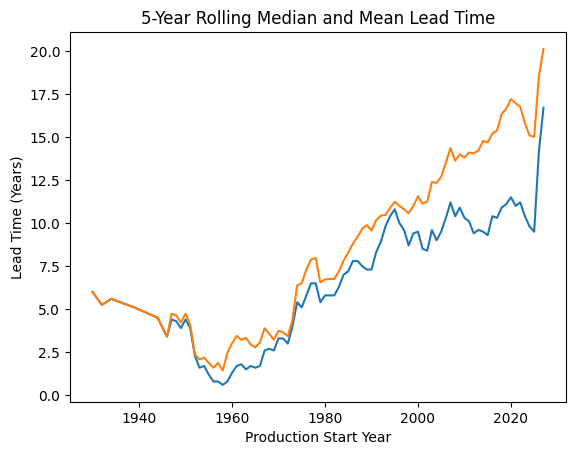

In [ ]:
# Convert columns to numeric
official_export_filter["Production start year"] = pd.to_numeric(official_export_filter["Production start year"], errors="coerce")
official_export_filter["Discovery to Start Year"] = pd.to_numeric(official_export_filter["Discovery to Start Year"], errors="coerce")

# Drop missing values
official_export_filter = official_export_filter.dropna(subset=["Production start year", "Discovery to Start Year"])

# Sort by production start year (proxy for time progression)
official_export_filter = official_export_filter.sort_values("Production start year")

# Group by production start year and compute annual median and mean
annual = official_export_filter.groupby("Production start year")["Discovery to Start Year"].agg(["median", "mean"]).reset_index()

# Calculate 5-year rolling statistics
annual["rolling_median"] = annual["median"].rolling(window=5, min_periods=3).mean()
annual["rolling_mean"] = annual["mean"].rolling(window=5, min_periods=3).mean()

# Plot (single plot, no specific colors)
plt.figure()
plt.plot(annual["Production start year"], annual["rolling_median"])
plt.plot(annual["Production start year"], annual["rolling_mean"])
plt.xlabel("Production Start Year")
plt.ylabel("Lead Time (Years)")
plt.title("5-Year Rolling Median and Mean Lead Time")
plt.show()

CODE FOR USING RAW DATABASE BELOW

---



In [ ]:
# bring in production data (covered when using official export)
goget_df = pd.read_csv(GOGET_data)

# copy status_timeline_merged
status_timeline_merged = status_timeline_merged.copy()

# strip "L" from Unit ID and create a new 'unit_id' column in goget_df
# Ensure 'Unit ID' is string before replacement to handle potential mixed types
goget_df['unit_id'] = goget_df['Unit ID'].astype(str).str.replace('L', '')

# Convert 'unit_id' in discovery_start_years to string type for merging
status_timeline_merged['unit_id'] = status_timeline_merged['unit_id'].astype(str)

# merge Country/Area on discovery_start_years using the harmonized 'unit_id' columns
status_timeline_merged = pd.merge(
    status_timeline_merged,
    goget_df[['unit_id', 'Country/Area','Unit Type', 'Fuel type', 'Production Type','Unit Name', 'Onshore/Offshore']], # Select the processed 'unit_id' and 'Country/Area' from goget_df
    left_on='unit_id',
    right_on='unit_id',
    how='left'
)

status_timeline_merged.head()

,id,order,status,substatus,statusDatasource,year,monthOrHalfYear,unit_id,created,modified,delayed,notes,Country/Area,Unit Type,Fuel type,Production Type,Unit Name,Onshore/Offshore
0,19332,1,discovered,,[193245],1983.0,None,100000308744,2025-09-10 16:46:00.892448+00:00,2026-01-23 19:04:23.595352+00:00,False,None,Canada,field,oil and gas,NaN,"Manir Oil and Gas Field (Alberta, Canada)",onshore
1,12875,2,operating,,[193468],2021.0,None,100000318339,2025-08-06 21:45:42.525836+00:00,2025-08-06 21:52:55.787924+00:00,False,None,Barbados,field,oil,conventional,Edgecumbe Oil Field (Barbados),onshore
2,19876,1,discovered,,[193245],1978.0,None,100000309032,2025-09-10 16:46:04.994321+00:00,2026-01-28 16:38:14.897388+00:00,False,None,Canada,field,gas,NaN,"Steve Gas Field (Alberta, Canada)",onshore
3,18460,1,discovered,,[193245],1904.0,None,100000308289,2025-09-10 16:45:54.774385+00:00,2026-01-23 19:04:23.920914+00:00,False,None,Canada,field,oil and gas,NaN,"Bow Island Oil and Gas Field (Alberta, Canada)",onshore
4,18461,2,operating,,[193647],2022.0,None,100000308289,2025-09-10 16:45:54.781304+00:00,2026-01-23 19:04:23.923107+00:00,False,None,Canada,field,oil and gas,NaN,"Bow Island Oil and Gas Field (Alberta, Canada)",onshore


In [ ]:
# merge production, covered when using export
# Ensure 'project_id' in prod_df and 'unit_id' in status_timeline_merged are of string type for merging
prod_df['project_id'] = prod_df['project_id'].astype(str)
status_timeline_merged['unit_id'] = status_timeline_merged['unit_id'].astype(str)

# Merge 'shared unit (million boe/y)' from prod_df onto status_timeline_merged
status_timeline_merged = pd.merge(
    status_timeline_merged,
    prod_df[['project_id', 'shared unit (million boe/y)']].drop_duplicates(subset=['project_id']),
    left_on='unit_id',
    right_on='project_id',
    how='left'
)

# Display the head of the updated DataFrame to verify the merge
display(status_timeline_merged.head())

,id,order,status,substatus,statusDatasource,year,monthOrHalfYear,unit_id,created,modified,delayed,notes,Country/Area,Unit Type,Fuel type,Production Type,Unit Name,Onshore/Offshore,project_id,shared unit (million boe/y)
0,12875,2,operating,,[193468],2021.0,None,100000318339,2025-08-06 21:45:42.525836+00:00,2025-08-06 21:52:55.787924+00:00,False,None,Barbados,field,oil,conventional,Edgecumbe Oil Field (Barbados),onshore,100000318339,0.064488
1,22532,3,operating,,[201259],2025.0,None,100000310877,2025-09-10 16:46:22.364291+00:00,2025-09-10 17:08:53.974794+00:00,False,None,China,field,gas,conventional,"Puguang Gas Field (Sichuan, China)",onshore,100000310877,49.744800
2,8076,1,discovered,,[193199],1992.0,None,100000302719,2025-08-06 21:45:07.427322+00:00,2025-11-12 23:22:34.146649+00:00,False,None,Mexico,field,oil and gas,conventional,"Alux Oil and Gas Field (Federal Offshore, Mexico)",offshore,NaN,NaN
3,8077,2,,,[],NaN,None,100000302719,2025-08-06 21:45:07.432341+00:00,2025-11-12 23:22:34.148719+00:00,False,None,Mexico,field,oil and gas,conventional,"Alux Oil and Gas Field (Federal Offshore, Mexico)",offshore,NaN,NaN
4,17136,2,operating,ramp up,[193191],1995.0,None,100000301072,2025-09-10 16:45:45.326477+00:00,2025-11-12 23:23:26.368907+00:00,False,None,Netherlands,field,oil and gas,conventional,K11-FB Oil and Gas Field (Netherlands),offshore,NaN,NaN


In [ ]:
# filter, covered below when using official export
# Define common filters for 'field' and 'conventional' production, excluding certain name prefixes
condition_main_filters = \
    (status_timeline_merged['Unit Type'] == 'field') & \
    (status_timeline_merged['Production Type'] == 'conventional')

# Define prefixes to filter out (e.g., 'FGP', 'Phase', 'Shale')
prefixes_to_filter = ['FGP', 'Phase','Shale','Redevelopment','Mad Dog Southwest','redevelopment','phase']
condition_no_prefixes = ~status_timeline_merged['Unit Name'].str.contains('|'.join(prefixes_to_filter), na=False)

# Define the specific condition to include 'Asset (Federal offshore, United States)'
# Escaping parentheses to treat them as literal characters, not regex groups
condition_asset_federal_offshore = status_timeline_merged['Unit Name'].str.contains(r'Asset \(Federal offshore, United States\)', na=False)
condition_asset_russia = (status_timeline_merged['Country/Area'] == 'Russia') & (status_timeline_merged['Unit Type'] == 'asset') #seeing how bringing in russia assets impacts data

# Combine all conditions: (Main filters AND No prefixes) OR (Asset (Federal offshore, United States))
final_filter = (condition_main_filters & condition_no_prefixes) | condition_asset_federal_offshore | condition_asset_russia

status_timeline_merged = status_timeline_merged[final_filter]

display(status_timeline_merged.head())

,id,order,status,substatus,statusDatasource,year,monthOrHalfYear,unit_id,created,modified,delayed,notes,Country/Area,Unit Type,Fuel type,Production Type,Unit Name,Onshore/Offshore
1,12875,2,operating,,[193468],2021.0,None,100000318339,2025-08-06 21:45:42.525836+00:00,2025-08-06 21:52:55.787924+00:00,False,None,Barbados,field,oil,conventional,Edgecumbe Oil Field (Barbados),onshore
10,22532,3,operating,,[201259],2025.0,None,100000310877,2025-09-10 16:46:22.364291+00:00,2025-09-10 17:08:53.974794+00:00,False,None,China,field,gas,conventional,"Puguang Gas Field (Sichuan, China)",onshore
11,8076,1,discovered,,[193199],1992.0,None,100000302719,2025-08-06 21:45:07.427322+00:00,2025-11-12 23:22:34.146649+00:00,False,None,Mexico,field,oil and gas,conventional,"Alux Oil and Gas Field (Federal Offshore, Mexico)",offshore
12,8077,2,,,[],NaN,None,100000302719,2025-08-06 21:45:07.432341+00:00,2025-11-12 23:22:34.148719+00:00,False,None,Mexico,field,oil and gas,conventional,"Alux Oil and Gas Field (Federal Offshore, Mexico)",offshore
13,17136,2,operating,ramp up,[193191],1995.0,None,100000301072,2025-09-10 16:45:45.326477+00:00,2025-11-12 23:23:26.368907+00:00,False,None,Netherlands,field,oil and gas,conventional,K11-FB Oil and Gas Field (Netherlands),offshore


In [ ]:
# load production from other code (covered when using export)
# load in recent production data
prod_df = pd.read_csv(qc_dump_folder + 'recent_production_byfuel_converted_df_2026-02-09_17-57-39.csv')

In [ ]:
import pandas as pd
from sqlalchemy import create_engine, text

# Database connection setup (copied from original cells)
DATABASE_URL = 'postgres://readonly:p8973ecd68569dabd2e8d1bc7bd5446d35a0d457487e0a783c83de2ec8a1043cc@ec2-54-243-187-12.compute-1.amazonaws.com:5432/d3o895iig4poii'
if DATABASE_URL.startswith('postgres:'):
    DATABASE_URL = DATABASE_URL.replace('postgres:', 'postgresql:')
engine = create_engine(DATABASE_URL)
conn = engine.connect()

# Function to convert SQL tables to dataframes (copied from original cell)
def get_sql_table(table_name):
   df = pd.read_sql(table_name,conn)
   return df

# Create status_timeline_merged DataFrame (copied from original cell qZgqjq4qF786)
status_timeline = get_sql_table("status_timeline")
goget_project = get_sql_table("goget_project")

# Perform an inner merge using unit_id from status_timeline and project_id from goget_project
status_timeline_filtered = status_timeline.merge(goget_project[['project_id']], left_on='unit_id', right_on='project_id', how='inner')

# Select only the original columns from status_timeline
status_timeline_merged = status_timeline_filtered[status_timeline.columns]

display(status_timeline_merged.head())

,id,order,status,substatus,statusDatasource,year,monthOrHalfYear,unit_id,created,modified,delayed,notes
0,19332,1,discovered,,[193245],1983.0,None,100000308744,2025-09-10 16:46:00.892448+00:00,2026-01-23 19:04:23.595352+00:00,False,None
1,12875,2,operating,,[193468],2021.0,None,100000318339,2025-08-06 21:45:42.525836+00:00,2025-08-06 21:52:55.787924+00:00,False,None
2,19876,1,discovered,,[193245],1978.0,None,100000309032,2025-09-10 16:46:04.994321+00:00,2026-01-28 16:38:14.897388+00:00,False,None
3,18460,1,discovered,,[193245],1904.0,None,100000308289,2025-09-10 16:45:54.774385+00:00,2026-01-23 19:04:23.920914+00:00,False,None
4,18461,2,operating,,[193647],2022.0,None,100000308289,2025-09-10 16:45:54.781304+00:00,2026-01-23 19:04:23.923107+00:00,False,None


In [ ]:
# --- Step 1: Prepare disco_to_start ---
# Assuming 'status_timeline_merged' DataFrame is already available from previous steps
disco_to_start = status_timeline_merged.copy()

# --- Step 2: Calculate Discovery and Start Years ---
# Discovery year = earliest status entry where status = "discovered"
disco_to_start['Discovery Year'] = status_timeline_merged[status_timeline_merged['status'] == 'discovered'].groupby('unit_id')['year'].transform('min')

# Start year = earliest status of "operating" with substatus "ramp up"
disco_to_start['Start Year'] = status_timeline_merged[(status_timeline_merged['status'] == 'operating') & (status_timeline_merged['substatus'] == 'ramp up')].groupby('unit_id')['year'].transform('min')

# --- Step 3: Merge and Calculate Duration ---
# Extract unique Discovery Year for each unit_id
discovery_years = disco_to_start.dropna(subset=['Discovery Year'])[['unit_id', 'Discovery Year']].drop_duplicates(subset=['unit_id'])

# Extract unique Start Year for each unit_id
start_years = disco_to_start.dropna(subset=['Start Year'])[['unit_id', 'Start Year']].drop_duplicates(subset=['unit_id'])

# Merge the two DataFrames on unit_id to get one row per unit_id
discovery_start_years = pd.merge(discovery_years, start_years, on='unit_id', how='outer')

# Calculate the discovery to start year for each unit. If both values are not blank Start Year - Discovery Year
discovery_start_years['Discovery to Start Year'] = discovery_start_years['Start Year'] - discovery_start_years['Discovery Year']

# Drop NaN values from 'Discovery to Start Year'
discovery_start_years = discovery_start_years.dropna(subset=['Discovery to Start Year'])

# add in missing 2025 data, for some reason this is excluded from the table of the export
# unit_id: 100001081837, 	Discovery Year: 1970	Start Year: 2025	Discovery to Start Year: 55
new_entries = [
    # {
    #     'unit_id': 100001081837, # Quiluma
    #     'Discovery Year': 1970,
    #     'Start Year': 2025,
    #     'Discovery to Start Year': 55
    # },
        {
        'unit_id': 100000310995, # Assa North-Ohaji South
        'Discovery Year': 1992,
        'Start Year': 2025,
        'Discovery to Start Year': 33
    },
# {
#         'unit_id': 100001081838, # Maboqueiro
#         'Discovery Year': 1995,
#         'Start Year': 2025,
#         'Discovery to Start Year': 30
#     },
# # {
#         'unit_id': 100000319529, # Shenandoah (WR051) - Beacon
#         'Discovery Year': 2009,
#         'Start Year': 2025,
#         'Discovery to Start Year': 16
#     },
# {
#         'unit_id': 100000319540, # Castile (KC736) - LLOG
#         'Discovery Year': 2011,
#         'Start Year': 2025,
#         'Discovery to Start Year': 14
#     },
# {
#         'unit_id': 100000319532, # Leon (KC642) - LLOG
#         'Discovery Year': 2011,
#         'Start Year': 2025,
#         'Discovery to Start Year': 14
#     },

# {
#         'unit_id': 100000318925, # Whale (AC772) - Shell
#         'Discovery Year': 2017,
#         'Start Year': 2025,
#         'Discovery to Start Year': 8
#     },
# {
#         'unit_id': 100000317955, # Ballymore (MC607) - Chevron
#         'Discovery Year': 2018,
#         'Start Year': 2025,
#         'Discovery to Start Year': 7
#     },
# {
#         'unit_id': 100000317960, # Dover (MC612) - Shell
#         'Discovery Year': 2018,
#         'Start Year': 2025,
#         'Discovery to Start Year': 7
# }
]

discovery_start_years = pd.concat([
    discovery_start_years,
    pd.DataFrame(new_entries)
], ignore_index=True)


# --- Step 4: Calculate the annual average discovery_start_years by start year ---
discovery_start_years_avg = discovery_start_years.groupby('Start Year')['Discovery to Start Year'].mean().reset_index()

# --- Step 5: Define Eras ---
eras = {
    '1900-1950': (1900, 1950),
    '1951-1989': (1951, 1989),
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2011-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# --- Step 6: Group by Era ---
# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years_avg
discovery_start_years_avg['Era'] = discovery_start_years_avg['Start Year'].apply(get_era)

# Group by 'Era' and calculate the mean of 'Discovery to Start Year'
discovery_start_years_by_era = discovery_start_years_avg.groupby('Era')['Discovery to Start Year'].mean().reset_index()

# --- Step 7: Display Results ---
display(discovery_start_years_by_era)

,Era,Discovery to Start Year
0,1900-1950,3.408333
1,1951-1989,4.254122
2,1990-1999,9.821542
3,2000-2009,12.344544
4,2011-2020,15.144897
5,2021-2024,15.266344
6,2025,14.200000
7,Other,11.333333


In [ ]:
# raw database - calacuate difference
era_2025_value = discovery_start_years_by_era[discovery_start_years_by_era['Era'] == '2025']['Discovery to Start Year'].iloc[0]
era_1990_1999_value = discovery_start_years_by_era[discovery_start_years_by_era['Era'] == '1990-1999']['Discovery to Start Year'].iloc[0]

difference = era_2025_value - era_1990_1999_value

# percent increase
percent_increase = (difference / era_1990_1999_value) * 100

print(f"The '2025' era was {difference:.2f} years longer than the '1990-1999' era in 'Discovery to Start Year'. A percent increase of {percent_increase}")

The '2025' era was 4.38 years longer than the '1990-1999' era in 'Discovery to Start Year'. A percent increase of 44.58015515363121


In [ ]:
import numpy as np

# Ensure 'unit_id' columns are of consistent type (string) for merging
discovery_start_years['unit_id'] = discovery_start_years['unit_id'].astype(str)
status_timeline_merged['unit_id'] = status_timeline_merged['unit_id'].astype(str)

# Merge 'Fuel type' from status_timeline_merged onto discovery_start_years
discovery_start_years_with_fuel = pd.merge(
    discovery_start_years,
    status_timeline_merged[['unit_id', 'Fuel type']].drop_duplicates(subset=['unit_id']),
    on='unit_id',
    how='left'
)

# Combine 'gas and condensate' with 'oil and gas'
discovery_start_years_with_fuel['Fuel type'] = discovery_start_years_with_fuel['Fuel type'].replace('gas and condensate', 'oil and gas')

# group unknown into oil and gas
discovery_start_years_with_fuel['Fuel type'] = discovery_start_years_with_fuel['Fuel type'].replace('', 'oil and gas')

# --- Define Eras (from previous cells for consistency) ---
eras = {
    '1900-1950': (1900, 1950),
    '1951-1989': (1951, 1989),
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2011-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# --- Function to map a year to an era (from previous cells) ---
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in the new DataFrame
discovery_start_years_with_fuel['Era'] = discovery_start_years_with_fuel['Start Year'].apply(get_era)

# Group by 'Era' and 'Fuel type' and calculate the mean of 'Discovery to Start Year'
discovery_start_years_by_era_fuel = discovery_start_years_with_fuel.groupby(['Era', 'Fuel type'])['Discovery to Start Year'].mean().reset_index()


In [ ]:
# Pivot the table so that 'Fuel type' becomes columns and 'Era' becomes rows
pivoted_fuel_analysis = discovery_start_years_by_era_fuel.pivot_table(
    index='Era',
    columns='Fuel type',
    values='Discovery to Start Year'
).reset_index()

# Rename the columns for clarity (optional, but good practice)
pivoted_fuel_analysis.columns.name = None # Remove the 'Fuel type' name from the columns index

# Display the pivoted DataFrame
display(pivoted_fuel_analysis.sort_values(by='Era'))

,Era,gas,oil,oil and gas
0,1900-1950,6.500000,5.727273,1.894737
1,1951-1989,3.735714,6.102041,5.198732
2,1990-1999,10.120690,9.754386,10.000000
3,2000-2009,11.464646,11.952381,13.044041
4,2011-2020,14.486486,14.648649,15.525641
5,2021-2024,18.738095,13.000000,14.393258
6,2025,12.500000,1.500000,13.882353
7,Other,NaN,NaN,0.000000


In [ ]:
# check X year discovery_start_years to see if it matches manual gathering
discovery_start_years[discovery_start_years['Start Year'] == 2016.0].sort_values(by='Discovery to Start Year', ascending=False)

,unit_id,Discovery Year,Start Year,Discovery to Start Year
2187,100000313005,1967.0,2016.0,49.0
1903,100000312311,1967.0,2016.0,49.0
1902,100000312309,1969.0,2016.0,47.0
1828,100000312161,1971.0,2016.0,45.0
1799,100000312100,1972.0,2016.0,44.0
963,100000301869,1975.0,2016.0,41.0
2186,100000312988,1977.0,2016.0,39.0
1538,100000310011,1980.0,2016.0,36.0
2304,100000317506,1981.0,2016.0,35.0
1585,100000310891,1983.0,2016.0,33.0


# Weighted Averages

### Merge production data and apply eras to `discovery_start_years`

First, I'll merge the `'shared unit (million boe/y)'` column from `status_timeline_merged` into `discovery_start_years`. Then, I'll apply the previously defined era groupings to this DataFrame to prepare for the weighted average calculation.

In [ ]:
# Ensure 'unit_id' columns are of consistent type (string) for merging
discovery_start_years['unit_id'] = discovery_start_years['unit_id'].astype(str)
status_timeline_merged['unit_id'] = status_timeline_merged['unit_id'].astype(str)

# Merge 'shared unit (million boe/y)' from status_timeline_merged onto discovery_start_years
discovery_start_years = pd.merge(
    discovery_start_years,
    status_timeline_merged[['unit_id', 'shared unit (million boe/y)']].drop_duplicates(subset=['unit_id']),
    on='unit_id',
    how='left'
)

iea_eras = {
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2010-2019': (2010, 2019),
    '2020-2024': (2020, 2024),
    '2025': (2025, 2025)
}

# Function to map a year to an era
def get_era(year, era_dict):
    for era_name, (start, end) in era_dict.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create 'Era' columns in discovery_start_years
discovery_start_years['Era'] = discovery_start_years['Start Year'].apply(lambda x: get_era(x, eras))
discovery_start_years['iea_eras'] = discovery_start_years['Start Year'].apply(lambda x: get_era(x, iea_eras))

### Calculate Weighted Average for original Eras

Now I'll calculate the weighted average of 'Discovery to Start Year' by the original `Era` groupings, using the 'shared unit (million boe/y)' as weights.

In [ ]:
# Define a function for weighted average
def weighted_average(df, value_col, weight_col):
    # Drop rows where either value or weight is NaN, as they can't contribute to the weighted average
    df_clean = df.dropna(subset=[value_col, weight_col])

    if df_clean[weight_col].sum() == 0:
        return float('nan') # Avoid division by zero if all weights are zero

    return (df_clean[value_col] * df_clean[weight_col]).sum() / df_clean[weight_col].sum()

# Group by 'Era' and calculate the weighted mean of 'Discovery to Start Year'
weighted_avg_discovery_by_era = discovery_start_years.groupby('Era').apply(
    lambda x: weighted_average(x, 'Discovery to Start Year', 'shared unit (million boe/y)')
).reset_index(name='Weighted Average Discovery to Start Year')

# Display the results, sorted by era for better readability
display(weighted_avg_discovery_by_era.sort_values(by='Era'))

/tmp/ipython-input-2493587627.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_avg_discovery_by_era = discovery_start_years.groupby('Era').apply(


,Era,Weighted Average Discovery to Start Year
0,1900-1950,2.730674
1,1951-1989,7.209109
2,1990-1999,16.924127
3,2000-2009,16.685670
4,2011-2020,24.346100
5,2021-2024,15.787864
6,2025,11.321016
7,Other,0.000000


### Calculate Weighted Average for IEA Eras

Finally, I'll calculate the weighted average of 'Discovery to Start Year' by the `iea_eras` groupings.

In [ ]:
# Group by 'iea_eras' and calculate the weighted mean of 'Discovery to Start Year'
weighted_avg_discovery_by_iea_era = discovery_start_years.groupby('iea_eras').apply(
    lambda x: weighted_average(x, 'Discovery to Start Year', 'shared unit (million boe/y)')
).reset_index(name='Weighted Average Discovery to Start Year')

# Display the results, sorted by era for better readability
display(weighted_avg_discovery_by_iea_era.sort_values(by='iea_eras'))

/tmp/ipython-input-928378402.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_avg_discovery_by_iea_era = discovery_start_years.groupby('iea_eras').apply(


,iea_eras,Weighted Average Discovery to Start Year
0,1990-1999,16.924127
1,2000-2009,16.685670
2,2010-2019,25.022707
3,2020-2024,15.527463
4,2025,11.321016
5,Other,6.891539


### Comparison of Weighted vs. Unweighted Averages for Original Eras

In [ ]:
# Merge the weighted and unweighted averages for the original eras
comparison_original_eras = pd.merge(
    discovery_start_years_by_era.rename(columns={'Discovery to Start Year': 'Unweighted Average'}),
    weighted_avg_discovery_by_era.rename(columns={'Weighted Average Discovery to Start Year': 'Weighted Average'}),
    on='Era',
    how='outer'
)

# Display the comparison, sorted by era
display(comparison_original_eras.sort_values(by='Era'))

,Era,Unweighted Average,Weighted Average
0,1900-1950,3.408333,2.730674
1,1951-1989,4.254122,7.209109
2,1990-1999,9.821542,16.924127
3,2000-2009,12.344544,16.685670
4,2011-2020,15.144897,24.346100
5,2021-2024,15.266344,15.787864
6,2025,15.653846,11.321016
7,Other,0.000000,0.000000


### Comparison of Weighted vs. Unweighted Averages for IEA Eras

In [ ]:
# compare to EIA figures
# use IEA Eras
iea_eras = {
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2010-2019': (2010, 2019),
    '2020-2024': (2020, 2024),
    '2025': (2025, 2025)
}

# --- Step 6: Group by Era ---
# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in iea_eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years_avg
discovery_start_years_avg['iea_eras'] = discovery_start_years_avg['Start Year'].apply(get_era)

# Group by 'Era' and calculate the mean of 'Discovery to Start Year'
discovery_start_years_by_iea_era = discovery_start_years_avg.groupby('iea_eras')['Discovery to Start Year'].mean().reset_index()

# --- Step 7: Display Results ---
display(discovery_start_years_by_iea_era)


,iea_eras,Discovery to Start Year
0,1990-1999,9.645907
1,2000-2009,12.146635
2,2010-2019,15.136840
3,2020-2024,14.847076
4,2025,15.653846
5,Other,3.939597


In [ ]:
# Merge the weighted and unweighted averages for the IEA eras
comparison_iea_eras = pd.merge(
    discovery_start_years_by_iea_era[['iea_eras', 'Discovery to Start Year']].rename(columns={'Discovery to Start Year': 'Unweighted Average'}),
    weighted_avg_discovery_by_iea_era.rename(columns={'Weighted Average Discovery to Start Year': 'Weighted Average'}),
    on='iea_eras',
    how='outer'
)

# Display the comparison, sorted by era
display(comparison_iea_eras.sort_values(by='iea_eras'))

NameError: name 'discovery_start_years_by_iea_era' is not defined

In [ ]:
# define IEA totals for comparison
iea_comp = {
    '1990-1999': 9.6,
    '2000-2009': 10.9,
    '2010-2019': 13.2,
    '2020-2024': 12.0,
}

# add IEA comparisons to table
discovery_start_years_by_iea_era['iea_comp'] = discovery_start_years_by_iea_era['iea_eras'].map(iea_comp)

discovery_start_years_by_iea_era

,iea_eras,Discovery to Start Year,iea_comp
0,1990-1999,9.645907,9.6
1,2000-2009,12.146635,10.9
2,2010-2019,15.136840,13.2
3,2020-2024,14.847076,12.0
4,2025,15.653846,NaN
5,Other,3.939597,NaN


# Country Analysis

In [ ]:
# Merge 'Country/Area' from status_timeline_merged into discovery_start_years
# First, ensure 'unit_id' columns are of consistent type (string) for merging
discovery_start_years['unit_id'] = discovery_start_years['unit_id'].astype(str)
status_timeline_merged['unit_id'] = status_timeline_merged['unit_id'].astype(str)

discovery_start_years = pd.merge(
    discovery_start_years,
    status_timeline_merged[['unit_id', 'Country/Area']].drop_duplicates(subset=['unit_id']),
    on='unit_id',
    how='left'
)

# Get average discovery to start by country
discovery_start_years_by_country = discovery_start_years.groupby('Country/Area')['Discovery to Start Year'].mean().reset_index()

# sort how to high to check for outliers
discovery_start_years_by_country = discovery_start_years_by_country.sort_values(by='Discovery to Start Year', ascending=False)

# display
discovery_start_years_by_country

,Country/Area,Discovery to Start Year
11,Cameroon,57.000000
44,Mozambique,42.500000
3,Argentina,39.000000
27,Hungary,32.875000
53,Philippines,24.000000
...,...,...
0,Albania,2.000000
17,Cuba,2.000000
62,Syria,1.000000
24,Germany,0.930435


In [ ]:
# load in regional defintions
regional_def = pd.read_csv('/content/drive/MyDrive/GOGET q1 2026/GOGET oil & gas extraction sites (main data set) - Country Names and Region Definitions - GOGET oil & gas extraction sites (main data set) - Country Names and Region Definitions.csv')

In [ ]:
# Ensure 'Country/Area' in discovery_start_years and 'GEM Standard Country Name' in regional_def are of consistent type (string) for merging
discovery_start_years['Country/Area'] = discovery_start_years['Country/Area'].astype(str)
regional_def['GEM Standard Country Name'] = regional_def['GEM Standard Country Name'].astype(str)

# Merge regional definitions onto discovery_start_years
discovery_start_years = pd.merge(
    discovery_start_years,
    regional_def[['GEM Standard Country Name', 'GEM region', 'GEM sub-region']],
    left_on='Country/Area',
    right_on='GEM Standard Country Name',
    how='left'
)

# Drop the redundant 'GEM Standard Country Name' column
discovery_start_years = discovery_start_years.drop(columns=['GEM Standard Country Name'])

# Display the head of the updated DataFrame to verify the merge
display(discovery_start_years.head())

,unit_id,Discovery Year,Start Year,Discovery to Start Year,shared unit (million boe/y),Era,iea_eras,Country/Area,GEM region,GEM sub-region
0,100000300001,1949.0,1951.0,2.0,NaN,1951-1989,Other,Austria,Europe,Western Europe
1,100000300002,2001.0,2009.0,8.0,0.066988,2000-2009,2000-2009,Brazil,Americas,Latin America and the Caribbean
2,100000300003,2005.0,2006.0,1.0,NaN,2000-2009,2000-2009,Brazil,Americas,Latin America and the Caribbean
3,100000300004,2005.0,2007.0,2.0,0.003281,2000-2009,2000-2009,Brazil,Americas,Latin America and the Caribbean
4,100000300005,2005.0,2007.0,2.0,NaN,2000-2009,2000-2009,Brazil,Americas,Latin America and the Caribbean


In [ ]:
# --- Step 4: Calculate the annual average discovery_start_years by start year ---
discovery_start_years_avg = discovery_start_years.groupby('Start Year')['Discovery to Start Year'].mean().reset_index()

# --- Step 5: Define Eras ---
eras = {
    '1900-1950': (1900, 1950),
    '1951-1989': (1951, 1989),
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2011-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# --- Step 6: Group by Era ---
# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years_avg
discovery_start_years_avg['Era'] = discovery_start_years_avg['Start Year'].apply(get_era)

# Group by 'Era' and calculate the mean and standard deviation of 'Discovery to Start Year'
discovery_start_years_by_era = discovery_start_years_avg.groupby('Era')['Discovery to Start Year'].agg(
    Mean=('mean'),
    Standard_Deviation=('std')
).reset_index()

# --- Step 7: Display Results ---
display(discovery_start_years_by_era)

,Era,Mean,Standard_Deviation
0,1900-1950,3.408333,2.840465
1,1951-1989,4.254122,2.561260
2,1990-1999,9.821542,1.652586
3,2000-2009,12.344544,1.985717
4,2011-2020,15.144897,2.447960
5,2021-2024,15.266344,2.321255
6,2025,15.653846,NaN
7,Other,0.000000,0.000000


In [ ]:
# export
discovery_start_years_by_era.to_csv(data_viz_fold + '/eras with std dev 2026 01 29.csv', index=False)

In [ ]:
# Define Eras (using the same definition as provided by the user)
eras = {
    '1900-1950': (1900, 1950),
    '1951-1989': (1951, 1989),
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2011-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years
discovery_start_years['Era'] = discovery_start_years['Start Year'].apply(get_era)

# Group by 'GEM sub-region' and 'Era' and calculate the mean of 'Discovery to Start Year'
discovery_start_years_by_region_era = discovery_start_years.groupby(['GEM region', 'Era'])['Discovery to Start Year'].mean().reset_index()

# Display the results
display(discovery_start_years_by_region_era.sort_values(by=['GEM region', 'Era']))

,GEM region,Era,Discovery to Start Year
0,Africa,1951-1989,4.960000
1,Africa,1990-1999,12.592593
2,Africa,2000-2009,13.576923
3,Africa,2011-2020,15.645161
4,Africa,2021-2024,14.450000
5,Africa,2025,25.333333
6,Americas,1900-1950,2.666667
7,Americas,1951-1989,2.862069
8,Americas,1990-1999,6.789474
9,Americas,2000-2009,11.729730


In [ ]:
# count unique countries in discovery_start_years
print(f"Number of countries in analysis: {len(discovery_start_years['Country/Area'].unique())}")

Number of countries in analysis: 76


In [ ]:
# save out discovery_start_years_by_region_era
discovery_start_years_by_region_era.to_csv(data_viz_fold + '/discovery_start_years_by_sub_region_era.csv')

In [ ]:
# set key country
key_country = 'Australia'

# --- Step 1: Prepare disco_to_start ---
# Assuming 'status_timeline_merged' DataFrame is already available from previous steps
disco_to_start = status_timeline_merged.copy()

# filter for key country
disco_to_start_country = disco_to_start[disco_to_start['Country/Area'] == key_country]

# --- Step 2: Calculate Discovery and Start Years ---
# Discovery year = earliest status entry where status = "discovered"
disco_to_start_country['Discovery Year'] = status_timeline_merged[status_timeline_merged['status'] == 'discovered'].groupby('unit_id')['year'].transform('min')

# Start year = earliest status of "operating" with substatus "ramp up"
disco_to_start_country['Start Year'] = status_timeline_merged[(status_timeline_merged['status'] == 'operating') & (status_timeline_merged['substatus'] == 'ramp up')].groupby('unit_id')['year'].transform('min')

# --- Step 3: Merge and Calculate Duration ---
# Extract unique Discovery Year for each unit_id
discovery_years = disco_to_start_country.dropna(subset=['Discovery Year'])[['unit_id', 'Discovery Year']].drop_duplicates(subset=['unit_id'])

# Extract unique Start Year for each unit_id
start_years = disco_to_start_country.dropna(subset=['Start Year'])[['unit_id', 'Start Year']].drop_duplicates(subset=['unit_id'])

# Merge the two DataFrames on unit_id to get one row per unit_id
disco_to_start_country = pd.merge(discovery_years, start_years, on='unit_id', how='outer')

# Calculate the discovery to start year for each unit. If both values are not blank Start Year - Discovery Year
disco_to_start_country['Discovery to Start Year'] = disco_to_start_country['Start Year'] - disco_to_start_country['Discovery Year']

# Drop NaN values from 'Discovery to Start Year'
disco_to_start_country = disco_to_start_country.dropna(subset=['Discovery to Start Year'])

# add in missing 2025 data, for some reason this is excluded from the table of the export
# unit_id: 100001081837, 	Discovery Year: 1970	Start Year: 2025	Discovery to Start Year: 55

# --- Step 4: Calculate the annual average discovery_start_years by start year ---
disco_to_start_country_avg = disco_to_start_country.groupby('Start Year')['Discovery to Start Year'].mean().reset_index()

# --- Step 5: Define Eras ---
eras = {
    '1900-1950': (1900, 1950),
    '1951-1989': (1951, 1989),
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2011-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# --- Step 6: Group by Era ---
# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years_avg
disco_to_start_country_avg['Era'] = disco_to_start_country_avg['Start Year'].apply(get_era)

# Group by 'Era' and calculate the mean of 'Discovery to Start Year'
disco_to_start_country_avg_by_era = disco_to_start_country_avg.groupby('Era')['Discovery to Start Year'].mean().reset_index()

# --- Step 7: Display Results ---
display(disco_to_start_country_avg_by_era)

/tmp/ipython-input-3550341296.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disco_to_start_country['Discovery Year'] = status_timeline_merged[status_timeline_merged['status'] == 'discovered'].groupby('unit_id')['year'].transform('min')
/tmp/ipython-input-3550341296.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disco_to_start_country['Start Year'] = status_timeline_merged[(status_timeline_merged['status'] == 'operating') & (status_timeline_merged['substatus'] == 'ramp up')].groupby('unit_id')['

,Era,Discovery to Start Year
0,2000-2009,5.000000
1,2011-2020,21.800000
2,2021-2024,19.333333
3,2025,19.000000


In [ ]:
# count rows in disco_to_start_country
print(f"Number of rows in analysis: {len(disco_to_start_country)}")

Number of rows in analysis: 14


In [ ]:
# set key country
key_country = 'Norway'

# --- Step 1: Prepare disco_to_start ---
# Assuming 'status_timeline_merged' DataFrame is already available from previous steps
disco_to_start = status_timeline_merged.copy()

# filter for key country
disco_to_start_country = disco_to_start[disco_to_start['Country/Area'] == key_country]

# --- Step 2: Calculate Discovery and Start Years ---
# Discovery year = earliest status entry where status = "discovered"
disco_to_start_country['Discovery Year'] = status_timeline_merged[status_timeline_merged['status'] == 'discovered'].groupby('unit_id')['year'].transform('min')

# Start year = earliest status of "operating" with substatus "ramp up"
disco_to_start_country['Start Year'] = status_timeline_merged[(status_timeline_merged['status'] == 'operating') & (status_timeline_merged['substatus'] == 'ramp up')].groupby('unit_id')['year'].transform('min')

# --- Step 3: Merge and Calculate Duration ---
# Extract unique Discovery Year for each unit_id
discovery_years = disco_to_start_country.dropna(subset=['Discovery Year'])[['unit_id', 'Discovery Year']].drop_duplicates(subset=['unit_id'])

# Extract unique Start Year for each unit_id
start_years = disco_to_start_country.dropna(subset=['Start Year'])[['unit_id', 'Start Year']].drop_duplicates(subset=['unit_id'])

# Merge the two DataFrames on unit_id to get one row per unit_id
disco_to_start_country = pd.merge(discovery_years, start_years, on='unit_id', how='outer')

# Calculate the discovery to start year for each unit. If both values are not blank Start Year - Discovery Year
disco_to_start_country['Discovery to Start Year'] = disco_to_start_country['Start Year'] - disco_to_start_country['Discovery Year']

# Drop NaN values from 'Discovery to Start Year'
disco_to_start_country = disco_to_start_country.dropna(subset=['Discovery to Start Year'])

# add in missing 2025 data, for some reason this is excluded from the table of the export
# unit_id: 100001081837, 	Discovery Year: 1970	Start Year: 2025	Discovery to Start Year: 55

# --- Step 4: Calculate the annual average discovery_start_years by start year ---
disco_to_start_country_avg = disco_to_start_country.groupby('Start Year')['Discovery to Start Year'].mean().reset_index()

# --- Step 5: Define Eras ---
eras = {
    '1900-1950': (1900, 1950),
    '1951-1989': (1951, 1989),
    '1990-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2011-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# --- Step 6: Group by Era ---
# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years_avg
disco_to_start_country_avg['Era'] = disco_to_start_country_avg['Start Year'].apply(get_era)

# Group by 'Era' and calculate the mean of 'Discovery to Start Year'
disco_to_start_country_avg_by_era = disco_to_start_country_avg.groupby('Era')['Discovery to Start Year'].mean().reset_index()

# --- Step 7: Display Results ---
display(disco_to_start_country_avg_by_era)

/tmp/ipython-input-4089784823.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disco_to_start_country['Discovery Year'] = status_timeline_merged[status_timeline_merged['status'] == 'discovered'].groupby('unit_id')['year'].transform('min')
/tmp/ipython-input-4089784823.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disco_to_start_country['Start Year'] = status_timeline_merged[(status_timeline_merged['status'] == 'operating') & (status_timeline_merged['substatus'] == 'ramp up')].groupby('unit_id')['

,Era,Discovery to Start Year
0,1951-1989,8.125000
1,1990-1999,14.425000
2,2000-2009,11.608333
3,2011-2020,15.871212
4,2021-2024,22.200000
5,2025,15.333333


In [ ]:
# check X year discovery_start_years to see if it matches manual gathering
disco_to_start_country_avg[disco_to_start_country_avg['Start Year'] == 2025.0].sort_values(by='Discovery to Start Year', ascending=False)

,Start Year,Discovery to Start Year,Era
3,2025.0,14.666667,2025


In [ ]:
# check onhore vs offshore start time
# Merge 'onshore/offshore' from status_timeline_merged into discovery_start_years
# First, ensure 'unit_id' columns are of consistent type (string) for merging
discovery_start_years['unit_id'] = discovery_start_years['unit_id'].astype(str)
status_timeline_merged['unit_id'] = status_timeline_merged['unit_id'].astype(str)

discovery_start_years = pd.merge(
    discovery_start_years,
    status_timeline_merged[['unit_id', 'Onshore/Offshore']].drop_duplicates(subset=['unit_id']),
    on='unit_id',
    how='left'
)

# Get average discovery to start by country
discovery_start_years_by_shore = discovery_start_years.groupby('Onshore/Offshore')['Discovery to Start Year'].mean().reset_index()

# sort how to high to check for outliers
discovery_start_years_by_shore = discovery_start_years_by_shore.sort_values(by='Discovery to Start Year', ascending=False)

# display
discovery_start_years_by_shore

,Onshore/Offshore,Discovery to Start Year
0,offshore,11.474658
1,onshore,9.718321
2,unknown,9.023256


In [ ]:
# calacuate difference
offshore_value = discovery_start_years_by_shore[discovery_start_years_by_shore['Onshore/Offshore'] == 'offshore']['Discovery to Start Year'].iloc[0]
onshore_value = discovery_start_years_by_shore[discovery_start_years_by_shore['Onshore/Offshore'] == 'onshore']['Discovery to Start Year'].iloc[0]

difference = offshore_value - onshore_value

# percent increase
percent_increase = (difference / offshore_value) * 100

print(f"The '2025' era was {difference:.2f} years longer than the '1990-1999' era in 'Discovery to Start Year'. A percent increase of {percent_increase}")

The '2025' era was 1.76 years longer than the '1990-1999' era in 'Discovery to Start Year'. A percent increase of 15.306229270953024


# Task
Group the `discovery_start_years` DataFrame by 'GEM region' and 'iea_eras', then calculate and display the mean of 'Discovery to Start Year' for each group, sorted by 'GEM region' and 'iea_eras'.

## calculate_regional_era_mean

### Subtask:
Group the `discovery_start_years` DataFrame by 'GEM region' and the specified 'iea_eras', then calculate the mean of 'Discovery to Start Year' for each group.


**Reasoning**:
To calculate the mean of 'Discovery to Start Year' for each combination of 'GEM region' and 'iea_eras', I need to group the 'discovery_start_years' DataFrame by these two columns and then apply the mean aggregation.



In [ ]:
discovery_start_years_by_region_iea_era = discovery_start_years.groupby(['GEM region', 'iea_eras'])['Discovery to Start Year'].mean().reset_index()

# Display the results
display(discovery_start_years_by_region_iea_era.sort_values(by=['GEM region', 'iea_eras']))

,GEM region,iea_eras,Discovery to Start Year
0,Africa,1990-1999,12.592593
1,Africa,2000-2009,13.576923
2,Africa,2010-2019,14.775862
3,Africa,2020-2024,16.750000
4,Africa,2025,25.333333
5,Africa,Other,4.960000
6,Americas,1990-1999,6.789474
7,Americas,2000-2009,11.729730
8,Americas,2010-2019,9.850000
9,Americas,2020-2024,10.844828


# Task
I will modify cell `D-bWLfBE8OMi` to calculate the median 'Discovery to Start Year' by era and fuel type, and then pivot the results for clear display.

Specifically, I will:
1. Apply the `get_era` function to the `official_export_filter` DataFrame to create an 'Era' column.
2. Group `official_export_filter` by 'Era' and 'Fuel type' and compute the median of 'Discovery to Start Year'.
3. Pivot the resulting DataFrame, setting 'Era' as the index, 'Fuel type' as columns, and the median 'Discovery to Start Year' as values.
4. Display the pivoted DataFrame.

## Modify Code to Calculate Median and Correct Pivoting

### Subtask:
Adjust the code in cell `D-bWLfBE8OMi` to first apply the `get_era` function to the `official_export_filter` DataFrame (which contains the 'Fuel type' column). Then, group this DataFrame by 'Era' and 'Fuel type' and calculate the *median* of 'Discovery to Start Year'. Finally, pivot the resulting DataFrame correctly to display the median lead times by era and fuel type.


**Reasoning**:
The previous code in cell `D-bWLfBE8OMi` resulted in a KeyError because the 'Fuel type' column was lost during concatenation. To fix this and fulfill the subtask, I need to directly apply the `get_era` function to `official_export_filter`, then group by 'Era' and 'Fuel type' to calculate the median 'Discovery to Start Year', and finally pivot the result to show median lead times by era and fuel type.



In [ ]:
# attempt to recreate using David's data download
# bring in official export
official_export = pd.read_csv(GOGET_official_data)

# apply filter logic:
# Define common filters for 'field' and 'conventional' production, excluding certain name prefixes
condition_main_filters = \
    (official_export['Production Type'] == 'conventional')

# Define prefixes to filter out (e.g., 'FGP', 'Phase', 'Shale')
prefixes_to_filter = ['FGP', 'Phase','Shale','Redevelopment','Mad Dog Southwest','redevelopment','phase']
condition_no_prefixes = ~official_export['Unit Name'].str.contains('|'.join(prefixes_to_filter), na=False)

# Combine all conditions: (Main filters AND No prefixes) OR (Asset (Federal offshore, United States))
final_filter = (condition_main_filters & condition_no_prefixes)

official_export_filter = official_export[final_filter]


# Calculate the discovery to start year for each unit. If both values are not blank Start Year - Discovery Year
official_export_filter['Discovery to Start Year'] = official_export_filter['Production start year'] - official_export_filter['Discovery year']

# Drop NaN values from 'Discovery to Start Year'
official_export_filter = official_export_filter.dropna(subset=['Discovery to Start Year'])

# add in missing 2025 data, for some reason this is excluded from the table of the export
# unit_id: 100001081837, 	Discovery Year: 1970	Start Year: 2025	Discovery to Start Year: 55
new_entries = [
    {
        'unit_id': 100001081837, # Quiluma
        'Discovery year': 1970,
        'Fuel type': 'gas',
        'Production start year': 2025,
        'Discovery to Start Year': 55
    },
    #     {
    #     'unit_id': 100000310995, # Assa North-Ohaji South
    #     'Discovery year': 1992,
    #     'Production start year': 2025,
    #     'Discovery to Start Year': 33
    # },
{
        'unit_id': 100001081838, # Maboqueiro
        'Discovery year': 1995,
        'Fuel type': 'gas',
        'Production start year': 2025,
        'Discovery to Start Year': 30
    },
]

official_export_filter = pd.concat([
    official_export_filter,
    pd.DataFrame(new_entries)
], ignore_index=True)


# --- Step 4: Calculate the annual average discovery_start_years by start year ---
official_export_filter_avg = official_export_filter.groupby('Production start year')['Discovery to Start Year'].mean().reset_index()
official_export_filter_median = official_export_filter.groupby('Production start year')['Discovery to Start Year'].median().reset_index()

# --- Step 5: Define Eras ---
# five year intervals
# eras = {
#     '1900-1954': (1900, 1954),
#     '1955-1994': (1955, 1994),
#     '1995-1999': (1995, 1999),
#     '2000-2009': (2000, 2004),
#     '2005-2014': (2005, 2014),
#     '2015-2020': (2015, 2020),
#     '2021-2024': (2021, 2024),
#     '2025': (2025, 2025)
# }
# # ten year intervals
eras = {
    '1900-1959': (1900, 1950),
    '1960-1980': (1951, 1989),
    '1981-1999': (1990, 1999),
    '2000-2009': (2000, 2009),
    '2010-2020': (2010, 2020),
    '2021-2024': (2021, 2024),
    '2025': (2025, 2025)
}

# # even buckets
# eras = {
#     '1900-1985': (1900, 1985),
#     '1956-2000': (1986, 2000),
#     '2001-2015': (2001, 2015),
#     '2016-2024': (2016, 2024),
#     '2025': (2025, 2025)
# }


# --- Step 6: Group by Era ---
# Function to map a year to an era
def get_era(year):
    for era_name, (start, end) in eras.items():
        if start <= year <= end:
            return era_name
    return 'Other'

# Apply the function to create an 'Era' column in discovery_start_years_avg
official_export_filter_avg['Era'] = official_export_filter_avg['Production start year'].apply(get_era)
official_export_filter_median['Era'] = official_export_filter_median['Production start year'].apply(get_era)

# Group by 'Era' and calculate the mean of 'Discovery to Start Year'
official_export_filter_by_era = official_export_filter_avg.groupby('Era')['Discovery to Start Year'].mean().reset_index()
official_export_filter_by_era_median = official_export_filter_median.groupby('Era')['Discovery to Start Year'].median().reset_index()

# --- Step 7: Display Results ---
display(official_export_filter_by_era)
display(official_export_filter_by_era_median)


# Apply the get_era function to the official_export_filter DataFrame
official_export_filter['Era'] = official_export_filter['Production start year'].apply(get_era)

# Group by 'Era' and 'Fuel type' and calculate the median of 'Discovery to Start Year'
median_by_era_fuel = official_export_filter.groupby(['Era', 'Fuel type'])['Discovery to Start Year'].median().reset_index()

# Pivot the median_by_era_fuel DataFrame
pivoted_median_by_era_fuel = median_by_era_fuel.pivot(
    index='Era',
    columns='Fuel type',
    values='Discovery to Start Year'
).reset_index()

# Display the pivoted DataFrame
display(pivoted_median_by_era_fuel)


/tmp/ipython-input-3051857468.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  official_export_filter['Discovery to Start Year'] = official_export_filter['Production start year'] - official_export_filter['Discovery year']


,Era,Discovery to Start Year
0,1900-1959,4.513889
1,1960-1980,5.249498
2,1981-1999,10.939448
3,2000-2009,13.146658
4,2010-2020,15.774739
5,2021-2024,14.976110
6,2025,15.125000
7,Other,22.000000


,Era,Discovery to Start Year
0,1900-1959,3.75
1,1960-1980,3.50
2,1981-1999,9.75
3,2000-2009,9.75
4,2010-2020,10.00
5,2021-2024,9.50
6,2025,8.50
7,Other,22.00


Fuel type,Era,gas,gas and condensate,oil,oil and gas
0,1900-1959,5.0,NaN,3.0,2.5
1,1960-1980,1.5,15.0,4.0,5.0
2,1981-1999,8.0,24.0,5.5,10.0
3,2000-2009,6.5,33.0,7.0,11.0
4,2010-2020,8.0,25.0,8.5,11.0
5,2021-2024,12.0,35.0,8.0,10.0
6,2025,8.0,19.0,3.0,9.5
7,Other,22.0,NaN,NaN,NaN


# Task
Calculate the percentage growth in 'Discovery to Start Year' for offshore fields and onshore fields separately, using the mean values from the '1960-1980' era as the base and the '2025' era as the comparison point. Then, compare these two percentage growths and provide a summary conclusion.

## Calculate Percentage Growth for Offshore Fields

### Subtask:
Extract the 'Discovery to Start Year' for the earliest comparable era (1960-1980) and the latest era (2025) from the `offshore_by_era` DataFrame. Calculate the percentage increase in 'Discovery to Start Year' for offshore fields between these two eras.


**Reasoning**:
To calculate the percentage growth for offshore fields, I will extract the 'Discovery to Start Year' values for the '1960-1980' and '2025' eras from the `offshore_by_era` DataFrame, then apply the percentage increase formula and print the result.



In [ ]:
offshore_1960_1980_value = offshore_by_era[offshore_by_era['Era'] == '1960-1980']['Discovery to Start Year'].iloc[0]
offshore_2025_value = offshore_by_era[offshore_by_era['Era'] == '2025']['Discovery to Start Year'].iloc[0]

offshore_percentage_growth = ((offshore_2025_value - offshore_1960_1980_value) / offshore_1960_1980_value) * 100

print(f"Percentage increase in 'Discovery to Start Year' for offshore fields between 1960-1980 and 2025: {offshore_percentage_growth:.2f}%")

Percentage increase in 'Discovery to Start Year' for offshore fields between 1960-1980 and 2025: 60.43%


**Reasoning**:
Now, I will extract the 'Discovery to Start Year' for the earliest comparable era (1960-1980) and the latest era (2025) from the `onshore_by_era` DataFrame. I will then calculate the percentage increase in 'Discovery to Start Year' for onshore fields between these two eras to fulfill the subtask.



In [ ]:
onshore_1960_1980_value = onshore_by_era[onshore_by_era['Era'] == '1960-1980']['Discovery to Start Year'].iloc[0]
onshore_2025_value = onshore_by_era[onshore_by_era['Era'] == '2025']['Discovery to Start Year'].iloc[0]

onshore_percentage_growth = ((onshore_2025_value - onshore_1960_1980_value) / onshore_1960_1980_value) * 100

print(f"Percentage increase in 'Discovery to Start Year' for onshore fields between 1960-1980 and 2025: {onshore_percentage_growth:.2f}%")

Percentage increase in 'Discovery to Start Year' for onshore fields between 1960-1980 and 2025: 268.53%


## Comparison and Conclusion of Percentage Growth

Comparing the percentage growth for offshore and onshore fields:

- **Offshore fields** showed a **60.43% increase** in 'Discovery to Start Year' between the 1960-1980 era and the 2025 era.
- **Onshore fields** showed a significantly higher **268.53% increase** in 'Discovery to Start Year' during the same period.

**Conclusion**: Onshore fields have experienced a substantially greater percentage increase in lead time (Discovery to Start Year) compared to offshore fields when comparing the 1960-1980 era to the 2025 era.

## Final Task

### Subtask:
Present the calculated percentage growth for both offshore and onshore fields and reiterate the conclusion regarding their comparative growth in 'Discovery to Start Year'.


## Summary:

### Q&A
The task asked to calculate the percentage growth in 'Discovery to Start Year' for offshore and onshore fields and to compare these growths.

### Data Analysis Key Findings
*   Offshore fields showed a 60.43% increase in 'Discovery to Start Year' between the 1960-1980 era and the 2025 era.
*   Onshore fields showed a significantly higher 268.53% increase in 'Discovery to Start Year' over the same period (1960-1980 to 2025).

### Insights or Next Steps
*   Onshore fields are experiencing a much more substantial increase in the time it takes from discovery to production compared to offshore fields.
*   Further investigation could explore the underlying reasons for the differential growth in lead time between offshore and onshore fields, such as technological advancements, regulatory changes, or economic factors.
